# Do listeners reward harmonic complexity? Chord complexity and popularity in jazz standards (RQ2)

**Author:** Calvin Pan
**Date created:** October 10, 2026
**Date last modified:** October 11, 2026

---

This is a fun side project I started alongside my Impact Evaluations class (LPPA 7220) in UVA Batten's Master of Public Policy program. It's the second half of the project. The first half, `jazzchords_pan_rq1_complexity.ipynb`, measures how complex each tune's harmony is.

**RQ2 (associational):** Are jazz standards with more complex harmony recorded more often by jazz musicians, or listened to more?

I use the five complexity measures from the RQ1 notebook: vocabulary tier (1–5), pitch-class count, dissonance (Huron 1994), surprisal (following [Cheung et al. 2019](https://doi.org/10.1016/j.cub.2019.09.067)), and tonal complexity (Weiß & Müller 2014). Each is averaged to the tune level.

**Data sources:**
- Tune-level complexity measures from `jazzchords_pan_rq1_complexity.ipynb`, built from the [iRb Corpus of Jazz Standards](https://zenodo.org/records/3546040) (CC BY 4.0).
- [JazzStandards.com](https://www.jazzstandards.com/compositions/index.htm) rankings of the top 1,000 standards. The [ranking](https://www.jazzstandards.com/overview.ranking.htm) is based on how many different jazz artists have recorded each tune on CD (the site only publishes the rank, not the raw counts).
- [Last.fm API](https://www.last.fm/api) listener and play counts (needs a free API key, see Section 3).

### NOTE: Run the RQ1 notebook first, and Section 3 needs a Last.fm API key.

This notebook loads `output/rq1_tune_level_complexity.csv`, which `jazzchords_pan_rq1_complexity.ipynb` saves.

Get a free Last.fm key at https://www.last.fm/api/account/create and paste it into a text file called `lastfm_api_key.txt` in this folder (it's in `.gitignore`, so the key never gets pushed to GitHub). Only the API key is needed, not the shared secret. Everything except Section 3 runs without one.

Last.fm's [API terms](https://www.last.fm/api/tos) ask you to "drop them a line" before using the API for research/academic purposes, and to only use the data non-commercially. I also shouldn't push the Last.fm data to a public GitHub repo, so `rawdata/` should go in `.gitignore`.

Folder structure:

challenge2_jazzchords/
                    -- jazzchords_pan_rq1_complexity.ipynb (run first)
                    -- jazzchords_pan_rq2_popularity.ipynb (this notebook)  
                    -- lastfm_api_key.txt (my Last.fm API key; gitignored)
                    -- rawdata (JazzStandards ranks, Last.fm cache)
                    -- output (tables + figures; also where the RQ1 files are loaded from)  

### 0. Install packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import re
import os
import time
import html
import unicodedata
import requests

### 1. Load the tune-level complexity measures from the RQ1 notebook

In [2]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPA_7220_Impact_Evals/python/impactevals/challenge2_jazzchords/"
rawdata_dir = dir + "rawdata/"
output_dir = dir + "output/"

os.makedirs(rawdata_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

In [3]:
# Load the tune-level measures saved at the end of the RQ1 notebook
tune_level = pd.read_csv(output_dir + "rq1_tune_level_complexity.csv")
tune_level["era"] = pd.Categorical(tune_level["era"], categories=["Pre-1930", "1930s", "1940s", "1950s", "1960s", "1970+"], ordered=True)

measures = ["tier", "n_pcs", "dissonance", "surprisal", "tonal_complexity"]
measure_labels = {"tier": "Vocabulary tier (1–5)",
                  "n_pcs": "Pitch classes",
                  "dissonance": "Dissonance",
                  "surprisal": "Surprisal (bits)",
                  "tonal_complexity": "Tonal complexity"}

# Checks
print(str(len(tune_level)) + " tunes")   # Should be 1186
tune_level.head()

1186 tunes


,tune_id,title,composer,year,key,meter,n_changes,era,minor_key,key_mode,...,tier,n_pcs,dissonance,surprisal,tonal_complexity,z_tier,z_n_pcs,z_dissonance,z_surprisal,z_tonal_complexity
0,26-2,26-2,"Coltrane, John",1959,F,4/4,58,1950s,0,Major key,...,3.000000,4.000000,-0.380681,3.962501,0.924056,-0.713355,-0.418898,0.170859,-0.641483,2.095865
1,500mileshigh,500 Miles High,"Corea, Chick",1972,e,4/4,22,1970+,1,Minor key,...,3.454545,4.136364,-0.451574,6.299225,0.843279,0.351668,0.121751,-0.962851,0.792976,0.844555
2,502blues,502 Blues,"Rowles, Jimmy",1966,a,3/4,33,1960s,1,Minor key,...,3.727273,4.242424,-0.364181,7.592469,0.910137,0.990682,0.542256,0.434727,1.586867,1.880246
3,52ndstreettheme,52nd Street Theme,"Monk, Thelonious",1948,C,4/4,48,1940s,0,Major key,...,2.437500,3.708333,-0.537545,3.884081,0.650942,-2.031321,-1.575287,-2.337679,-0.689624,-2.134964
4,920special,9.20 Special,"Warren, Earl",1945,C,4/4,50,1940s,0,Major key,...,3.520000,4.140000,-0.352158,8.123443,0.795024,0.505032,0.136169,0.626993,1.912820,0.097030


### 2. Outcome #1: how often is each tune recorded? (JazzStandards.com rank)
JazzStandards.com ranks the top 1,000 standards by how many different jazz artists have recorded each one on CD. It only publishes the **rank**, not the counts, so I use two outcomes:
1. `js_top1000`: 1 if the tune is in the top 1,000 at all (defined for all 1,186 iRb tunes).
2. `js_pop` = −log(rank): higher = recorded more often (only defined for ranked tunes).

The site's robots.txt allows crawling, and this is only 10 pages. I add a 1-second pause between requests anyway and save the result, so it only gets scraped once.

In [4]:
js_path = rawdata_dir + "jazzstandards_ranks.csv"

if not os.path.exists(js_path):
    js_rows = []
    for page in range(1, 11):
        url = "https://www.jazzstandards.com/compositions/index.htm" if page == 1 else "https://www.jazzstandards.com/compositions/index" + str(page) + ".htm"
        r = requests.get(url, headers={"User-Agent": "Academic research script (UVA LPPA 7220 class project)"}, timeout=30)
        r.encoding = "windows-1252"
        # Each row looks like: <td>rank</td><td>year</td><td><a href="...">Title</a>
        for rank, year, href, title in re.findall(r'<tr class="JSContentsLine"><td align="right">(\d+)<br></td><td align="center">([^<]*)<br></td><td>&nbsp;<a href="([^"]+)">(.*?)</a>', r.text):
            js_rows.append({"js_rank": int(rank), "js_year": year, "js_title": html.unescape(title), "js_url": href})
        time.sleep(1)   # Be polite
    pd.DataFrame(js_rows).to_csv(js_path, index=False)

js = pd.read_csv(js_path)
print(str(len(js)) + " ranked standards")   # Should be 1000
js.head()

1000 ranked standards


,js_rank,js_year,js_url,js_title
0,1,1930,https://www.jazzstandards.com/compositions-0/b...,Body and Soul
1,2,1939,https://www.jazzstandards.com/compositions-0/a...,All the Things You Are
2,3,1935,https://www.jazzstandards.com/compositions-0/s...,Summertime
3,4,1944,https://www.jazzstandards.com/compositions-0/r...,'Round Midnight
4,5,1935,https://www.jazzstandards.com/compositions-0/i...,I Can't Get Started (with You)


**Matching titles.** iRb and JazzStandards.com spell titles differently ("Surrey With The Fringe On The Top" vs. "The Surrey with the Fringe on Top", "Best Thing For You Is Me, The", "Makin' Whoopee" vs. "Making Whoopee"). I standardize both (lowercase, drop punctuation and parentheses, drop a leading "The/A", treat "-in'" as "-ing"). I checked the remaining near-misses by hand against year and composer, and the true matches are in `MANUAL_MATCHES`.

I deliberately don't use automatic fuzzy matching, because it produces false matches like "Blue Monk" → "Blue Moon" and "Night Train" → "Freight Train."

In [5]:
def title_key(title):
    t = unicodedata.normalize("NFKD", str(title)).encode("ascii", "ignore").decode()
    t = t.lower().replace("&", "and")
    t = re.sub(r"\(.*?\)|\[.*?\]", "", t)       # Drop parentheses/brackets
    t = re.sub(r"\b(\w+)in'", r"\1ing", t)       # Makin' → making
    t = re.sub(r"\b'?till?\b", "til", t)         # Till / 'til / til → til
    t = re.sub(r"[^a-z0-9 ]", "", t)             # Drop punctuation
    t = re.sub(r"^(the|a|an) ", "", t.strip())   # Drop leading article
    return t.replace(" ", "")

# iRb writes "Best Thing For You Is Me, The" → move the article to the front
tune_level["title_clean"] = tune_level["title"].str.replace(r"^(.*), (The|A|An)$", r"\2 \1", regex=True)

# Hand-checked matches (iRb title → JazzStandards.com title)
MANUAL_MATCHES = {
    "Our Love is Here to Stay": "Love Is Here to Stay",
    "Mac The Knife": "Mack the Knife",
    "In A Mellow Tone (In A Mellotone)": "In a Mellotone",
    "I Can't Believe...You're In Love...": "I Can't Believe That You're in Love with Me",
    "Milestones-New": "Milestones",                       # The 1958 modal "Milestones" (JazzStandards lists it as 1958)
    "Surrey With The Fringe On The Top": "The Surrey with the Fringe on Top",
    "Bess You Is My Woman": "Bess, You Is My Woman Now",
    "Tisket A Tasket, A": "A-Tisket, A-Tasket",
    "Nandis": "Nardis",                                   # Typo in iRb; same year (1959)
    "I'm Through With Love": "I'm Thru with Love",
    "I Get Along Without You": "I Get Along Without You Very Well",
    "Jumpin With Symphony Sid": "Jumpin' with Symphony Sid",
    "You Brought A New Kind Of Love": "You Brought a New Kind of Love to Me",
    "Everything I Love": "Ev'rything I Love",
    "Best Thing For You Is Me, The": "The Best Thing for You",
    "Is You Is Or Is You Ain't (Ma' Baby)": "Is You Is or Is You Ain't My Baby?",
    "What Are You Doing New Years": "What Are You Doing New Year's Eve?",
}

tune_level["match_key"] = tune_level["title"].map(MANUAL_MATCHES).fillna(tune_level["title_clean"]).apply(title_key)
js["match_key"] = js["js_title"].apply(title_key)

# Drop the merge columns first if this cell is re-run
tune_level = tune_level.drop(columns=["js_rank", "js_title", "js_year", "js_url"], errors="ignore")
tune_level = tune_level.merge(js[["match_key", "js_rank", "js_title"]], on="match_key", how="left")
tune_level["js_top1000"] = tune_level["js_rank"].notna().astype(int)
tune_level["js_pop"] = -np.log(tune_level["js_rank"])

# Checks
print(str(tune_level["js_top1000"].sum()) + " of " + str(len(tune_level)) + " iRb tunes are in the JazzStandards.com top 1,000")

657 of 1186 iRb tunes are in the JazzStandards.com top 1,000


### 3. Outcome #2: total listeners and plays across all recordings of a tune (Last.fm)
A tune like "Autumn Leaves" has hundreds of recordings, so I want *total* listening across all of them. The pipeline for each tune:

1. **`track.search`** on the tune's title, up to `MAX_PAGES` pages of results. Each result is one recording, and Last.fm gives its listener count directly in the search results.
2. **Keep only recordings whose title actually matches** (after stripping "- Remastered 1999", "(Live)", etc.) and that have at least `MIN_LISTENERS` listeners.
3. **`artist.getInfo`** on each artist to get their tags, so I can **keep only jazz artists**. Without this filter, "Autumn Leaves" also picks up Ed Sheeran's unrelated song with the same name. I also save each artist's total listeners as a control for fame.
4. **`track.getInfo`** for play counts. This is one call per recording, which is the slow part, so I only get plays for each tune's `PLAYCOUNT_TOP_N` most-listened recordings. Listening is very top-heavy, so the top recordings make up most of the plays.

Total listeners double-counts people who listened to more than one version. That's fine here, since the question is about overall listening to the tune, not unique people.

**Limitation:** the jazz filter checks the *artist*, not the *song*. So if a jazz-tagged artist has a different song with the same title, it still gets counted. For example, Amy Winehouse's own "Just Friends" (not the 1931 standard) shows up under "Just Friends." About 7% of all listening in the final data comes from artists whose top tag isn't jazz-related. Some of those are real versions of the standard (Etta James, Elis Regina) and some aren't, so ~7% is a rough upper bound on this kind of mix-up.

**Speed.** Last.fm doesn't publish an exact rate limit in its current terms, but the commonly cited limit is about 5 requests per second. I throttle to 4 per second (`SECONDS_BETWEEN_CALLS = 0.25`). Every response is saved to `rawdata/lastfm/` as it comes in, so the run can be stopped and restarted without redoing calls (and Last.fm's terms require caching anyway).

In [6]:
# Read the Last.fm API key from a text file, so the key doesn't end up on GitHub
# lastfm_api_key.txt is in .gitignore. To set it up, paste just the key into that file.
key_path = dir + "lastfm_api_key.txt"
LASTFM_API_KEY = open(key_path).read().strip() if os.path.exists(key_path) else ""

In [7]:
# Settings
MAX_PAGES = 4                 # Up to 4 pages x 50 results = the top 200 search results per tune
RESULTS_PER_PAGE = 50
MIN_LISTENERS = 1000          # Ignore recordings with fewer than 1,000 listeners. In the pilot this kept 94.5% of jazz listening with less than half the artist lookups (100 → ~12 hour run, 1,000 → ~5-6 hours)
PLAYCOUNT_TOP_N = 20          # Get play counts for each tune's top 20 jazz recordings
SECONDS_BETWEEN_CALLS = 0.25  # Max 4 calls per second
JAZZ_TAG_WORDS = ["jazz", "bop", "swing", "bossa", "big band", "crooner", "standards", "dixieland", "ragtime"]

lastfm_dir = rawdata_dir + "lastfm/"
os.makedirs(lastfm_dir, exist_ok=True)
search_cache = lastfm_dir + "search_results.csv"
artist_cache = lastfm_dir + "artist_info.csv"
track_cache = lastfm_dir + "track_info.csv"

**Runtime estimate (before the pilot).** Upper bound on calls with the settings above:

In [8]:
n_tunes = len(tune_level)
max_search_calls = n_tunes * MAX_PAGES
max_track_calls = n_tunes * PLAYCOUNT_TOP_N
guess_artist_calls = 45000    # From the pilot: ~50 unique artists per tune at MIN_LISTENERS = 1000, and artists barely overlap across tunes
seconds_per_call = 0.3        # 0.25s throttle + network time (pilot averaged 0.31s per call)

total_calls = max_search_calls + max_track_calls + guess_artist_calls
print("Search calls (max):      " + f"{max_search_calls:,}")
print("Artist calls (guess):    " + f"{guess_artist_calls:,}")
print("Play-count calls (max):  " + f"{max_track_calls:,}")
print("Total:                   " + f"{total_calls:,}" + " calls ≈ " + str(round(total_calls * seconds_per_call / 3600, 1)) + " hours (upper bound)")
print("Listeners only (search step alone): ≈ " + str(round(max_search_calls * seconds_per_call / 60)) + " minutes")

Search calls (max):      4,744
Artist calls (guess):    45,000
Play-count calls (max):  23,720
Total:                   73,464 calls ≈ 6.1 hours (upper bound)
Listeners only (search step alone): ≈ 24 minutes


In [9]:
# Last.fm helper functions
LASTFM_URL = "https://ws.audioscrobbler.com/2.0/"
session = requests.Session()
session.headers["User-Agent"] = "JazzChordComplexity/0.1 (UVA LPPA 7220 class project)"
last_call = [0.0]    # Time of the last call (in a list so the function can update it)
api_calls = [0]      # Running count of calls made

def lastfm_call(method, **params):
    params.update(method=method, api_key=LASTFM_API_KEY, format="json")
    for attempt in range(5):
        wait = SECONDS_BETWEEN_CALLS - (time.time() - last_call[0])   # Throttle
        if wait > 0:
            time.sleep(wait)
        last_call[0] = time.time()
        api_calls[0] += 1
        try:
            data = session.get(LASTFM_URL, params=params, timeout=20).json()
        except (requests.RequestException, ValueError):
            time.sleep(5 * (attempt + 1))                              # Network hiccup: wait and retry
            continue
        if data.get("error") in (10, 26):
            raise ValueError("Last.fm says the API key is invalid or suspended: " + data.get("message", ""))
        if data.get("error") in (8, 11, 16, 29):                       # Backend error / offline / temporarily unavailable / rate limited
            time.sleep(5 * (attempt + 1))
            continue
        return data
    return {}

def as_list(x):
    # Last.fm sometimes returns a dict instead of a list when there's only one result
    if isinstance(x, dict):
        return [x]
    return x if isinstance(x, list) else []

def load_cache(path):
    return pd.read_csv(path, keep_default_na=False, na_values=[""]) if os.path.exists(path) else pd.DataFrame()

def append_cache(rows, path):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def clean_track_key(name):
    # "Autumn Leaves - Remastered 1999" → "autumnleaves"
    return title_key(re.split(r" - | – ", str(name))[0])

def is_jazz_artist(tags):
    return any(word in tags for word in JAZZ_TAG_WORDS)

In [10]:
# The three steps of the pipeline. Each one skips anything already in its cache.

def search_step(tune_df):
    done = set(load_cache(search_cache).get("tune_id", []))
    for i, (tune_id, query) in enumerate(zip(tune_df["tune_id"], tune_df["search_title"])):
        if tune_id in done:
            continue
        rows = []
        for page in range(1, MAX_PAGES + 1):
            data = lastfm_call("track.search", track=query, limit=RESULTS_PER_PAGE, page=page)
            matches = as_list(data.get("results", {}).get("trackmatches", {}).get("track", []))
            for t in matches:
                rows.append({"tune_id": tune_id, "page": page, "track": t.get("name"), "artist": t.get("artist"),
                             "listeners": int(t.get("listeners", 0) or 0), "mbid": t.get("mbid", "")})
            # Stop early if this was the last page, or results have dropped below the listener floor
            if len(matches) < RESULTS_PER_PAGE or max(int(t.get("listeners", 0) or 0) for t in matches) < MIN_LISTENERS:
                break
        if not rows:
            rows = [{"tune_id": tune_id, "page": 0}]     # Placeholder so we know this tune was searched
        append_cache(rows, search_cache)
        if i % 50 == 0:
            print("  searched " + str(i) + "/" + str(len(tune_df)) + " tunes (" + str(api_calls[0]) + " calls so far)")

def matching_recordings(tune_df):
    # Search results whose title matches the tune and that clear the listener floor
    results = load_cache(search_cache).dropna(subset=["track"])
    results = results.merge(tune_df[["tune_id", "match_key", "title_clean"]], on="tune_id")
    results["track_key"] = results["track"].apply(clean_track_key)
    keep = (results["track_key"] == results["match_key"]) | (results["track_key"] == results["title_clean"].apply(title_key))
    results = results[keep & (results["listeners"] >= MIN_LISTENERS)]
    return results.drop_duplicates(subset=["tune_id", "artist", "track"])

def artist_step(artists):
    done = set(load_cache(artist_cache).get("artist", []))
    todo = [a for a in pd.unique(artists) if a not in done]
    print("  " + str(len(todo)) + " artists to look up")
    rows = []
    for i, artist in enumerate(todo):
        data = lastfm_call("artist.getInfo", artist=artist, autocorrect=0).get("artist", {})
        tags = [t.get("name", "").lower() for t in as_list((data.get("tags") or {}).get("tag", []))]
        stats = data.get("stats", {})
        rows.append({"artist": artist, "artist_listeners": int(stats.get("listeners", 0) or 0),
                     "artist_playcount": int(stats.get("playcount", 0) or 0), "artist_tags": "; ".join(tags)})
        if len(rows) == 100 or i == len(todo) - 1:   # Save every 100 artists
            append_cache(rows, artist_cache)
            rows = []

def playcount_step(recordings):
    cache = load_cache(track_cache)
    done = set(zip(cache.get("artist", []), cache.get("track", [])))
    todo = recordings[[(a, t) not in done for a, t in zip(recordings["artist"], recordings["track"])]]
    print("  " + str(len(todo)) + " recordings to get play counts for")
    rows = []
    for i, (artist, track) in enumerate(zip(todo["artist"], todo["track"])):
        data = lastfm_call("track.getInfo", artist=artist, track=track, autocorrect=0).get("track", {})
        rows.append({"artist": artist, "track": track, "playcount": int(data.get("playcount", 0) or 0)})
        if len(rows) == 100 or i == len(todo) - 1:
            append_cache(rows, track_cache)
            rows = []

def run_lastfm_pipeline(tune_df):
    print("Step 1: search")
    search_step(tune_df)
    recordings = matching_recordings(tune_df)
    print("Step 2: artist tags")
    artist_step(recordings["artist"])
    recordings = recordings.merge(load_cache(artist_cache).drop_duplicates("artist"), on="artist", how="left")
    recordings["artist_tags"] = recordings["artist_tags"].fillna("")
    recordings = recordings[recordings["artist_tags"].apply(is_jazz_artist)]
    print("Step 3: play counts")
    recordings["listener_rank"] = recordings.groupby("tune_id")["listeners"].rank(ascending=False, method="first")
    playcount_step(recordings[recordings["listener_rank"] <= PLAYCOUNT_TOP_N])
    recordings = recordings.merge(load_cache(track_cache).drop_duplicates(["artist", "track"]), on=["artist", "track"], how="left")
    return recordings

In [11]:
# Search on the JazzStandards.com title when there is one (cleaner), otherwise the cleaned iRb title
# Drop anything in parentheses: searching "Autumn Leaves (Les Feuilles Mortes)" only finds versions with that exact long title, and misses Cannonball, Bill Evans, etc.
tune_level["search_title"] = (tune_level["js_title"].fillna(tune_level["title_clean"])
                              .str.replace(r"\(.*?\)|\[.*?\]|\.\.\.|\?", " ", regex=True)
                              .str.replace(r"\s+", " ", regex=True)
                              .str.strip())

**Pilot run.** Before the full run, I run the whole pipeline on 15 random tunes, time it, and scale up to all 1,186 tunes. Pilot results are cached, so the full run doesn't redo them.

**What the pilot found (October 10, 2026):** 1,854 calls in 568 seconds (about 124 calls per tune, 0.31s per call). With `MIN_LISTENERS = 100`, that projected to a ~12.5 hour full run. Most of that was artist lookups, since each tune had ~100 different artists and they barely overlap across tunes. Recordings with under 1,000 listeners only made up ~5% of jazz listening, so I raised `MIN_LISTENERS` to 1,000, which cut the full run to ~5–6 hours.

In [12]:
if LASTFM_API_KEY == "":
    print("No API key yet: paste it into lastfm_api_key.txt (see the NOTE at the top).")
elif os.path.exists(rawdata_dir + "lastfm_recordings_jazz.csv"):
    print("Full run already done, so skipping the pilot (it would just re-read the cache). Pilot results are in the markdown above.")
else:
    pilot = tune_level.sample(15, random_state=100)
    calls_before = api_calls[0]
    start = time.time()
    pilot_recordings = run_lastfm_pipeline(pilot)
    elapsed = time.time() - start
    pilot_calls = api_calls[0] - calls_before

    calls_per_tune = pilot_calls / len(pilot)
    projected_hours = elapsed / len(pilot) * len(tune_level) / 3600
    print("Pilot: " + str(pilot_calls) + " calls in " + str(round(elapsed)) + "s (" + str(round(calls_per_tune)) + " calls per tune)")
    print("Projected full run: ~" + f"{calls_per_tune * len(tune_level):,.0f}" + " calls ≈ " + str(round(projected_hours, 1)) + " hours")
    print("(This overestimates a bit: artists that show up for many tunes only get looked up once.)")
    display(pilot_recordings.sort_values("listeners", ascending=False).head(10)[["tune_id", "artist", "track", "listeners", "playcount", "artist_tags"]])

Full run already done, so skipping the pilot (it would just re-read the cache). Pilot results are in the markdown above.


**Full run.** This takes a few hours (see the pilot estimate above), so run it overnight. If it gets interrupted, just re-run this cell and it picks up where it left off.

In [13]:
RUN_FULL = False   # Set to True when ready

if RUN_FULL and LASTFM_API_KEY != "":
    recordings = run_lastfm_pipeline(tune_level)
    recordings.to_csv(rawdata_dir + "lastfm_recordings_jazz.csv", index=False)

# Aggregate to the tune level (if the full run has been done)
recordings_path = rawdata_dir + "lastfm_recordings_jazz.csv"
tune_level = tune_level.drop(columns=["n_recordings", "total_listeners", "total_playcount_topN", "log_listeners", "log_playcount"], errors="ignore")
if os.path.exists(recordings_path):
    recordings = pd.read_csv(recordings_path)
    tune_listens = recordings.groupby("tune_id").agg(n_recordings=("track", "size"),
                                                     total_listeners=("listeners", "sum"),
                                                     total_playcount_topN=("playcount", "sum"))
    tune_level = tune_level.merge(tune_listens, left_on="tune_id", right_index=True, how="left")
    tune_level[["n_recordings", "total_listeners", "total_playcount_topN"]] = tune_level[["n_recordings", "total_listeners", "total_playcount_topN"]].fillna(0)
    tune_level["log_listeners"] = np.log1p(tune_level["total_listeners"])
    tune_level["log_playcount"] = np.log1p(tune_level["total_playcount_topN"])
    display(tune_level.sort_values("total_listeners", ascending=False)[["title", "n_recordings", "total_listeners", "total_playcount_topN"]].head(15))
else:
    print("No Last.fm data yet: Table 4 will only include the JazzStandards.com outcomes.")

,title,n_recordings,total_listeners,total_playcount_topN
329,Fly Me To The Moon,84.0,2851561.0,12859472.0
990,Summertime,60.0,2619535.0,6890975.0
364,"Girl From Ipanema, The",62.0,2538699.0,11258966.0
730,My Funny Valentine,113.0,2083524.0,7601880.0
1121,What A Wonderful World,43.0,1883508.0,9781345.0
63,Autumn Leaves,89.0,1773629.0,5143800.0
1108,"Way You Look Tonight, The",97.0,1684237.0,5444757.0
134,Body And Soul,118.0,1683922.0,3608365.0
120,Blue In Green,50.0,1681886.0,7494710.0
544,I've Got You Under My Skin,66.0,1673286.0,5628326.0


### 4. Results: is harmonic complexity associated with being recorded or listened to more?
Each cell in Table 4 is a **separate regression** of an outcome on one standardized complexity measure, controlling for era, key mode, and meter, with robust (HC1) standard errors. Coefficients are the change in the outcome per 1 SD more complexity.

- `js_top1000` is a linear probability model (coefficient = change in the probability of being in the top 1,000).
- `js_pop` = −log(rank), so positive = recorded by more artists. Ranked tunes only.
- `log_listeners` / `log_playcount` = log(1 + total listeners / plays) across jazz recordings.

**These are associations, not causal effects.** Complexity isn't randomly assigned: era, composer, whether the tune came from a Broadway show, lyrics, and famous definitive recordings all affect both harmony and popularity. There's also reverse causality (popular tunes get edited by more iReal users, who tend to add extensions) and selection (iRb only contains tunes that already made it into the canon).

In [14]:
outcomes = {"js_top1000": "In JazzStandards top 1,000", "js_pop": "−log(JazzStandards rank)"}
if "log_listeners" in tune_level.columns:
    outcomes.update({"log_listeners": "log(total Last.fm listeners)", "log_playcount": "log(top-" + str(PLAYCOUNT_TOP_N) + " Last.fm plays)"})

table4 = pd.DataFrame(index=[measure_labels[m] for m in measures] + ["N tunes"], columns=list(outcomes.values()))
for y, y_label in outcomes.items():
    for m in measures:
        fit = smf.ols(y + " ~ z_" + m + " + C(era) + minor_key + C(meter_group)", data=tune_level.dropna(subset=[y])).fit(cov_type="HC1")
        b, se, p = fit.params["z_" + m], fit.bse["z_" + m], fit.pvalues["z_" + m]
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
        table4.loc[measure_labels[m], y_label] = f"{b:.3f}{stars} ({se:.3f})"
    table4.loc["N tunes", y_label] = str(int(fit.nobs))

table4.to_csv(output_dir + "table4_rq2_regressions.csv")
table4

,"In JazzStandards top 1,000",−log(JazzStandards rank),log(total Last.fm listeners),log(top-20 Last.fm plays)
Vocabulary tier (1–5),0.008 (0.012),0.052 (0.040),0.035 (0.076),0.033 (0.083)
Pitch classes,0.006 (0.013),0.026 (0.035),0.042 (0.072),0.044 (0.079)
Dissonance,0.002 (0.012),0.088** (0.039),-0.012 (0.068),-0.027 (0.074)
Surprisal (bits),-0.054*** (0.014),-0.182*** (0.041),-0.087 (0.089),-0.081 (0.098)
Tonal complexity,0.013 (0.012),0.138*** (0.047),-0.032 (0.073),-0.053 (0.080)
N tunes,1186,657,1186,1186


#### Table 4b: Inverted-U check (squared term)
Same regressions as Table 4, but adding each measure's square. A **negative** squared term means an inverted U: tunes in the middle of the complexity range do best, and both very simple and very complex tunes do worse. Figure 3 below shows the raw shape.

In [15]:
table4b = pd.DataFrame(index=[measure_labels[m] for m in measures], columns=list(outcomes.values()))
for y, y_label in outcomes.items():
    for m in measures:
        fit = smf.ols(y + " ~ z_" + m + " + I(z_" + m + "**2) + C(era) + minor_key + C(meter_group)", data=tune_level.dropna(subset=[y])).fit(cov_type="HC1")
        sq = [p for p in fit.params.index if p.startswith("I(")][0]    # Name of the squared term
        b, se, p = fit.params[sq], fit.bse[sq], fit.pvalues[sq]
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
        table4b.loc[measure_labels[m], y_label] = f"{b:.3f}{stars} ({se:.3f})"

table4b.to_csv(output_dir + "table4b_rq2_quadratic.csv")
table4b

,"In JazzStandards top 1,000",−log(JazzStandards rank),log(total Last.fm listeners),log(top-20 Last.fm plays)
Vocabulary tier (1–5),0.000 (0.005),-0.055*** (0.011),0.022 (0.027),0.029 (0.029)
Pitch classes,0.003 (0.004),-0.029*** (0.009),0.023 (0.019),0.029 (0.020)
Dissonance,0.001 (0.005),-0.045** (0.020),0.029 (0.029),0.035 (0.031)
Surprisal (bits),0.015* (0.008),-0.000 (0.033),0.038 (0.055),0.031 (0.061)
Tonal complexity,-0.011* (0.006),-0.051* (0.031),-0.035 (0.036),-0.037 (0.039)


#### Figure 3: Binned scatterplots
Psychology research suggests an **inverted U** between complexity and liking (Berlyne's "Wundt curve"; Cheung et al. 2019 find a version of this for chord progressions). Here I split tunes into 10 equal-sized bins on each measure and plot the share of tunes in the JazzStandards top 1,000 for each bin (or mean log listeners, once the Last.fm data is in). Unlike Table 4b, these are raw averages with no controls for era.

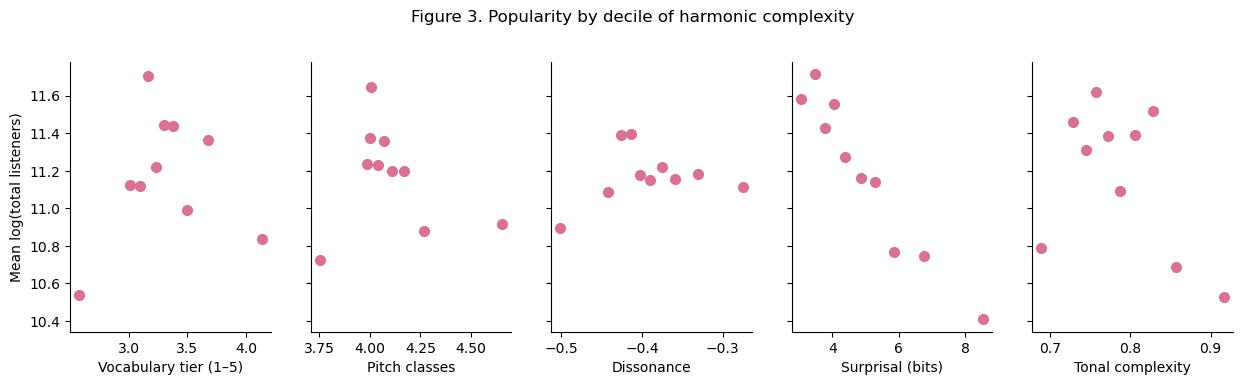

In [16]:
y = "log_listeners" if "log_listeners" in tune_level.columns else "js_top1000"

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=True)
for ax, m in zip(axes, measures):
    bins = pd.qcut(tune_level[m].rank(method="first"), 10, labels=False)   # Rank first so ties don't break qcut
    binned = tune_level.groupby(bins).agg(x=(m, "mean"), y=(y, "mean"))
    ax.plot(binned["x"], binned["y"], color="palevioletred", marker="o", markersize=7, linewidth=0)
    ax.set_xlabel(measure_labels[m])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Share in top 1,000" if y == "js_top1000" else "Mean log(total listeners)")
fig.suptitle("Figure 3. Popularity by decile of harmonic complexity", y=1.03)
plt.savefig(output_dir + "fig3_binscatter_rq2.png", dpi=200, bbox_inches="tight")
plt.show()

### Conclusion:
The Last.fm full run finished overnight: 37,000+ API calls in about 3 hours, covering 23,240 jazz recordings of 1,142 of the 1,186 tunes. (I had to re-run 53 tunes after realizing that searching with parentheses in the title, e.g. "Autumn Leaves (Les Feuilles Mortes)," was missing most of the recordings.)

**What musicians record (JazzStandards.com):** Tunes with more surprising progressions are less likely to be in the top 1,000 (−5.4 percentage points per SD), and are ranked lower among the ranked tunes. Tier, pitch classes, and dissonance have a significant inverted U with rank (Table 4b): tunes in the middle of the complexity range get recorded by the most artists.

**What listeners play (Last.fm):** None of the five measures is significantly related to total listeners or plays once I control for era, key, and meter, either linearly (Table 4) or with a squared term (Table 4b). The raw binned scatterplot (Figure 3) does show listening falling as surprisal goes up, but that mostly goes away with the era controls. Newer tunes are both more surprising *and* less listened to, so era is doing most of the work there.

So in this data, harmonic complexity seems to matter more for which tunes *musicians* pick up than for how much *listeners* play them. Both are associations, not causal effects. The other caveats: iRb only includes tunes that already made it into the canon, Last.fm users skew young and online, `MIN_LISTENERS = 1000` drops ~5% of jazz listening, and ~7% of listening may come from different songs with the same title (see Section 3).

**Next steps: getting to a causal claim.** Complexity isn't randomly assigned, so the regressions above can't say whether complexity *causes* anything. Some designs that could:
1. **Within-tune comparison of recordings:** compare different recordings of the *same* tune that harmonize it differently (e.g. a straight "Autumn Leaves" vs. a heavily reharmonized one), with tune fixed effects. This holds the melody, lyrics, and era fixed. The catch is that iRb has one chart per tune, not per recording, so I'd have to transcribe each recording's chords by ear (or use audio chord recognition). Artists who reharmonize might also differ in other ways (tempo, instrumentation, label).
2. **Randomized listening experiment:** the cleanest option. Take ~20 standards, make a simple version (triads) and a complex version (extensions/alterations) of each chart, and render both in iReal Pro with the same melody, tempo, and instruments. Then randomly assign listeners (on Prolific, or classmates) to one version and measure enjoyment ratings, or whether they choose to keep listening. Random assignment identifies the causal effect of harmonic complexity on enjoyment, though synthetic backing tracks and short clips limit how far it generalizes.
3. **Within-artist / within-album fixed effects:** compare tracks on the *same album* (same artist, label, promotion, and release date) that differ in harmonic complexity, using track-level Last.fm listeners. This controls for artist fame and promotion, but the artist still chose which tunes to record.
4. **Difference-in-differences around fake-book chart changes:** when a widely used fake book (e.g. the original *Real Book* in the 1970s, or later corrected editions) printed a tune with richer reharmonized changes, compare how often that tune got recorded before vs. after, relative to tunes whose charts didn't change. Recordings per year could come from MusicBrainz or Discogs. This needs parallel pre-trends between the two groups of tunes.
5. **Instrumental variable (probably a stretch):** something that shifts harmonic complexity but only affects popularity through complexity, e.g. whether the composer was a pianist (pianists might write denser harmony). The exclusion restriction is shaky, since pianist-composers probably differ in other ways too.

Other next steps that don't get at causality but would make the associations more believable: limit the sample to tunes written before ~1960 so every tune has had decades to get recorded, and add tunes that *didn't* become standards (e.g. all songs from a set of Broadway shows) so the sample isn't conditioned on success.